# 14 – Release Date Visualization

This notebook explores patterns across movie release dates from `data/features/09_popularity_features.csv`:
1. **Movie Count by Release Decade** (Bar Chart)
2. **Average Target Log Popularity by Release Decade** (Bar Chart)
3. **Movie Counts by Release Decade and Month** (Heatmap)

In [7]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from pathlib import Path

# Set project root path (2 levels above notebooks/visualization/)
PROJECT_ROOT = Path.cwd().parent.parent
INPUT_PATH = PROJECT_ROOT / "data" / "features" / "09_popularity_features.csv"

# Load dataset
df = pd.read_csv(INPUT_PATH)
print(f"Dataset shape: {df.shape}")

Dataset shape: (45430, 34)


## 1. Movie Count by Release Decade

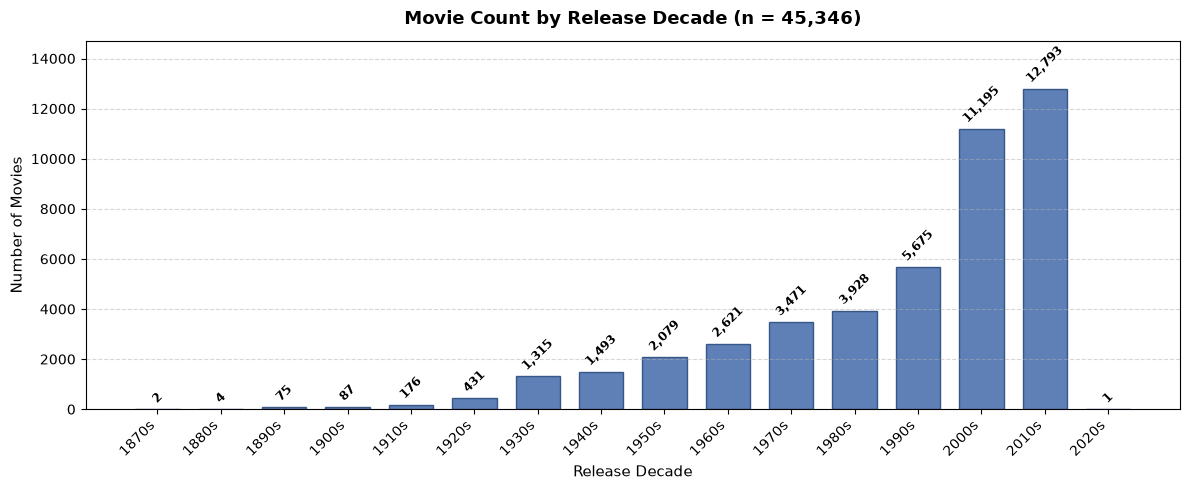

In [8]:
# Compute count per decade
decade_counts = df["release_decade"].dropna().astype(int).value_counts().sort_index()
decade_labels = [f"{d}s" for d in decade_counts.index]

plt.figure(figsize=(12, 5))
bars = plt.bar(decade_labels, decade_counts.values, color="#4C72B0", edgecolor="#2B4C7E", width=0.7, alpha=0.9)

# Annotate bar values
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0, height + 150, f"{int(height):,}",
             ha="center", va="bottom", fontsize=8.5, fontweight="semibold", rotation=45)

plt.title(f"Movie Count by Release Decade (n = {decade_counts.sum():,})", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Release Decade", fontsize=11)
plt.ylabel("Number of Movies", fontsize=11)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.ylim(0, max(decade_counts.values) * 1.15)
plt.tight_layout()
plt.show()

## 2. Average Target Log Popularity by Release Decade

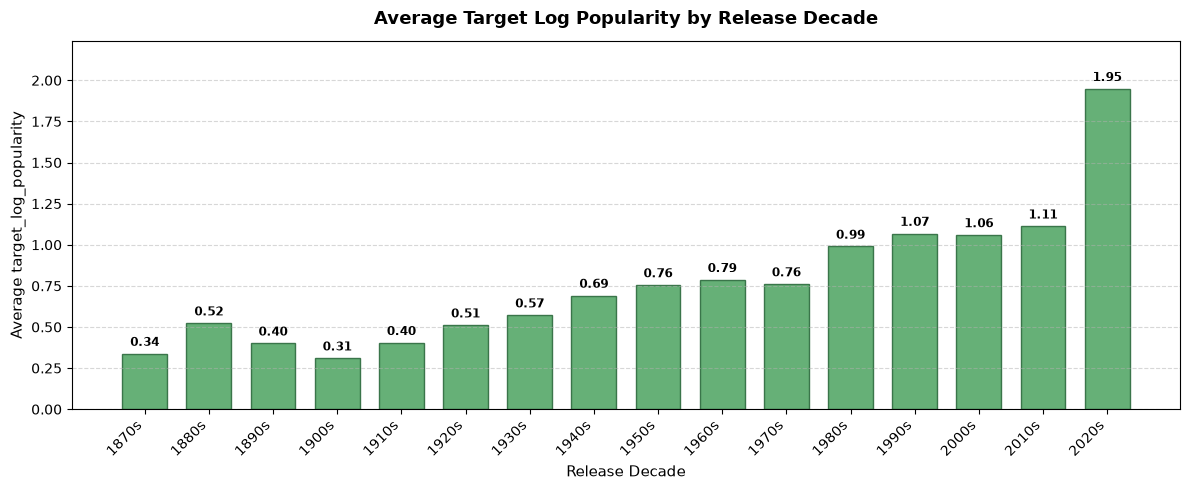

In [9]:
# Compute mean popularity per decade
avg_pop = df.groupby("release_decade")["target_log_popularity"].mean()

plt.figure(figsize=(12, 5))
bars = plt.bar([f"{int(d)}s" for d in avg_pop.index], avg_pop.values,
               color="#55A868", edgecolor="#2D6A3E", width=0.7, alpha=0.9)

# Annotate mean values
for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width() / 2.0, height + 0.03, f"{height:.2f}",
             ha="center", va="bottom", fontsize=8.5, fontweight="semibold")

plt.title("Average Target Log Popularity by Release Decade", fontsize=13, fontweight="bold", pad=12)
plt.xlabel("Release Decade", fontsize=11)
plt.ylabel("Average target_log_popularity", fontsize=11)
plt.xticks(rotation=45, ha="right", fontsize=10)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.ylim(0, max(avg_pop.values) * 1.15)
plt.tight_layout()
plt.show()

## 3. Heatmap of Movie Counts by Release Decade and Month

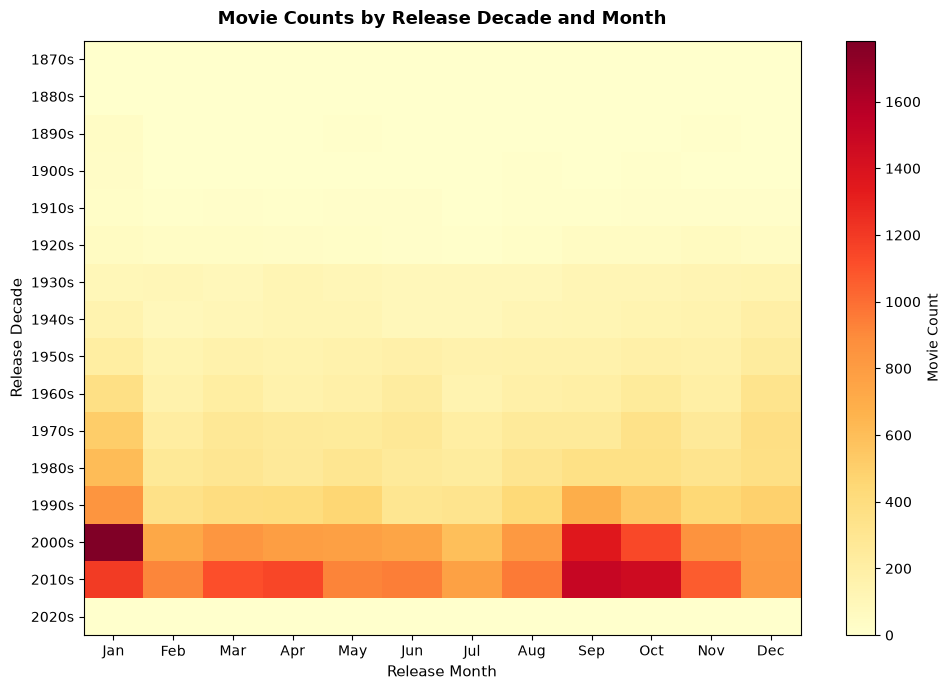

In [10]:
# Cross-tabulate decade and month counts
heatmap_data = pd.crosstab(
    df["release_decade"].dropna().astype(int),
    df["release_month"].dropna().astype(int)
)

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
decades = [f"{d}s" for d in heatmap_data.index]

plt.figure(figsize=(10, 7))
plt.imshow(heatmap_data.values, cmap="YlOrRd", aspect="auto")
plt.colorbar(label="Movie Count")

plt.xticks(range(12), months, fontsize=10)
plt.yticks(range(len(decades)), decades, fontsize=10)
plt.xlabel("Release Month", fontsize=11)
plt.ylabel("Release Decade", fontsize=11)
plt.title("Movie Counts by Release Decade and Month", fontsize=13, fontweight="bold", pad=12)
plt.tight_layout()
plt.show()

## 4. Average Target Log Popularity by Release Year

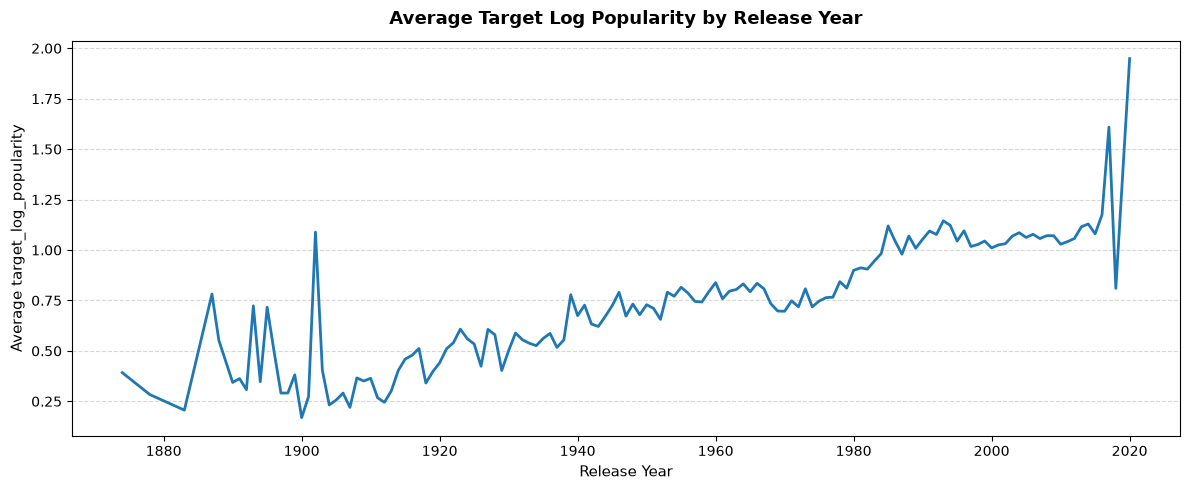

In [11]:
# Compute mean popularity per release year
avg_pop_year = (
    df.groupby("release_year")["target_log_popularity"]
    .mean()
    .dropna()
    .sort_index()
)

plt.figure(figsize=(12, 5))
plt.plot(
    avg_pop_year.index,
    avg_pop_year.values,
    linewidth=2
)

plt.title(
    "Average Target Log Popularity by Release Year",
    fontsize=13,
    fontweight="bold",
    pad=12
)
plt.xlabel("Release Year", fontsize=11)
plt.ylabel("Average target_log_popularity", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

**Insight:** Average target log popularity generally increases over time, with movies released in more recent years showing higher average popularity. Earlier years show greater fluctuations, likely because fewer movies are represented in those years.

## 5. Average Target Log Popularity by Release Month

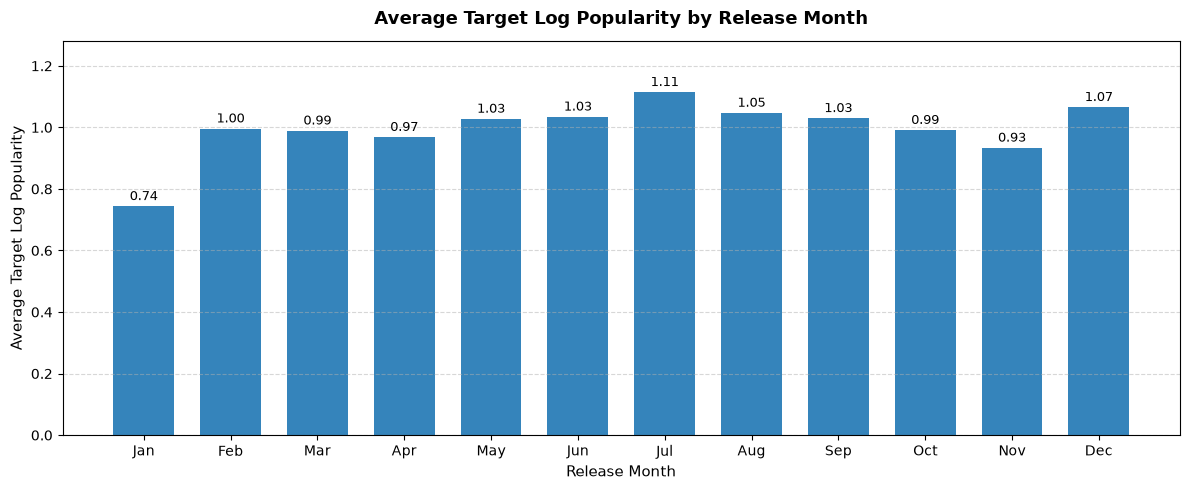

In [12]:
# Compute average target log popularity by release month
avg_pop_month = (
    df.groupby("release_month")["target_log_popularity"]
    .mean()
    .reindex(range(1, 13))
)

months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun",
          "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

plt.figure(figsize=(12, 5))

bars = plt.bar(
    months,
    avg_pop_month.values,
    width=0.7,
    alpha=0.9
)

# Annotate mean values
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 0.01,
        f"{height:.2f}",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.title(
    "Average Target Log Popularity by Release Month",
    fontsize=13,
    fontweight="bold",
    pad=12
)
plt.xlabel("Release Month", fontsize=11)
plt.ylabel("Average Target Log Popularity", fontsize=11)
plt.grid(axis="y", linestyle="--", alpha=0.5)
plt.ylim(0, max(avg_pop_month.values) * 1.15)

plt.tight_layout()
plt.show()

**Insight:** Average target log popularity is relatively consistent across most release months, but July has the highest average popularity (1.11), followed by December (1.07). January has the lowest average popularity (0.74).

## 6. Key Takeaways

1. **Release Volume Growth:** Movie releases increased substantially over time, particularly after 1980, with the 2000s and 2010s containing a large portion of the dataset.

2. **Popularity Across Decades:** Average `target_log_popularity` generally increases across release decades, with more recent decades showing higher average popularity than early cinema.

3. **Yearly Popularity Trend:** The release-year visualization shows the same overall upward trend at a finer level. Average popularity generally increases for more recent release years, although individual years show some fluctuations.

4. **Popularity by Release Month:** Popularity is relatively consistent across most months. July has the highest average `target_log_popularity` (1.11), followed by December (1.07), while January has the lowest (0.74).

5. **Release Timing:** The decade-month heatmap shows that movie releases become much more concentrated in recent decades, with noticeable differences in release volume across months.